# Example notebook

In [1]:
import scanpy as sc
import squidpy as sq
import diffsvg as dvg

/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_h5ad("/home/lehnerl/Arbeit/data/HiWi/both_conditions_5_7_without_noise.h5ad")

In [3]:
sq.tl.var_by_distance(
    adata, cluster_key="Dentate_Gyrus", groups="anchor", library_key="condition", covariates="condition"
)

In [4]:
adata.obsm["design_matrix"]

,Dentate_Gyrus,condition,anchor,anchor_raw
aaabncdp-1,outside,wildtype,0.333524,1321.582997
aaacifle-1,outside,wildtype,0.331894,1315.123685
aaadpmhm-1,outside,wildtype,0.350915,1390.492982
aaaegbnf-1,outside,wildtype,0.348516,1380.988101
aaaejcdp-1,outside,wildtype,0.356986,1414.550496
...,...,...,...,...
oijlpmjb-1,outside,TgCRND8,0.809131,3353.118921
oijmjakb-1,outside,TgCRND8,0.829792,3438.738477
oikbcigb-1,outside,TgCRND8,0.824830,3418.175635
oikbfpkg-1,outside,TgCRND8,0.829809,3438.809115


In [4]:
sc.pp.normalize_total(adata, inplace=True)
sc.pp.log1p(adata)
sc.pp.scale(adata, max_value=10)

/tmp/ipykernel_3186/330756641.py:1: UserWarning: Some cells have zero counts
  sc.pp.normalize_total(adata, inplace=True)
/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/functools.py:982: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [5]:
dvg.pp.bin_obs(
    adata, genes=adata.var_names, anchor="anchor", condition="condition", design_matrix="design_matrix", n_bins=50
)

/home/lehnerl/Arbeit/github/HiWi/diffsvg/src/diffsvg/pp/utils.py:353: RuntimeWarning: invalid value encountered in cast
  bin_assignment = np.clip(np.rint(all_anchor_vals * n_bins).astype(int), 0, n_bins)


In [6]:
setup = dvg.tl.setup_model(adata)

In [8]:
setup

DiffSVGModelSetup(binned=BinnedData(genes=['2010300C02Rik', 'Abca7', 'Acsbg1', 'Acta2', 'Acvrl1', 'Adamts2', 'Adamtsl1', 'Adgrl4', 'Aldh1a2', 'Aldh1l1', 'Angpt1', 'Ano1', 'Apod', 'Apoe', 'Aqp4', 'Arc', 'Arhgap12', 'Arhgap25', 'Arhgap6', 'Arhgef28', 'Aspg', 'B2m', 'Bcl11b', 'Bdnf', 'Bhlhe22', 'Bhlhe40', 'Btbd11', 'C1qa', 'C1qb', 'C1qc', 'C3', 'C4a', 'C4b', 'Cabp7', 'Cacna2d2', 'Calb1', 'Calb2', 'Car4', 'Carmn', 'Cbln1', 'Cbln4', 'Ccn2', 'Cd14', 'Cd24a', 'Cd300c2', 'Cd33', 'Cd44', 'Cd53', 'Cd63', 'Cd68', 'Cd69', 'Cd74', 'Cd93', 'Cdh13', 'Cdh20', 'Cdh4', 'Cdh6', 'Cdh9', 'Chat', 'Chodl', 'Chrm2', 'Cldn5', 'Clmn', 'Clu', 'Cnp', 'Cntn6', 'Cntnap4', 'Cntnap5b', 'Cobll1', 'Col19a1', 'Col1a1', 'Col6a1', 'Cort', 'Cplx3', 'Cpne4', 'Cpne6', 'Cpne8', 'Crh', 'Cryab', 'Csf1r', 'Cspg4', 'Cst3', 'Ctsa', 'Ctsb', 'Ctsd', 'Ctsh', 'Ctss', 'Ctsz', 'Cux2', 'Cwh43', 'Cx3cr1', 'Cxcl10', 'Cyba', 'Cyp1b1', 'Dcn', 'Deptor', 'Dkk2', 'Dkk3', 'Dner', 'Dpy19l1', 'Dpyd', 'Ebf3', 'Emcn', 'Epha4', 'Eya4', 'Fcer1g', 'Fcg

In [7]:
dvg.tl.fit_model(adata, setup, n_workers=4)

Fitting DiffSVG models:  13%|█▎        | 45/347 [01:25<11:50,  2.35s/it] /home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 347/347 [10:40<00:00,  1.85s/it]


<Axes: xlabel='$\\int f_0 - f_1$', ylabel='$-\\log_{10}(p)$'>

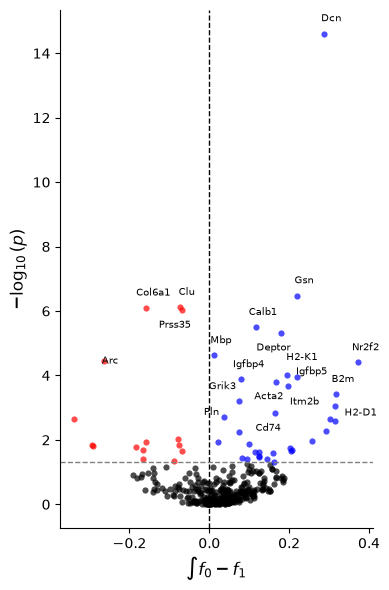

In [10]:
dvg.pl.plot_volcano(adata.varm["dsvg_stats"], n_label=20)

<Axes: xlabel='$\\int f_0 - f_1$', ylabel='$-\\log_{10}(p)$'>

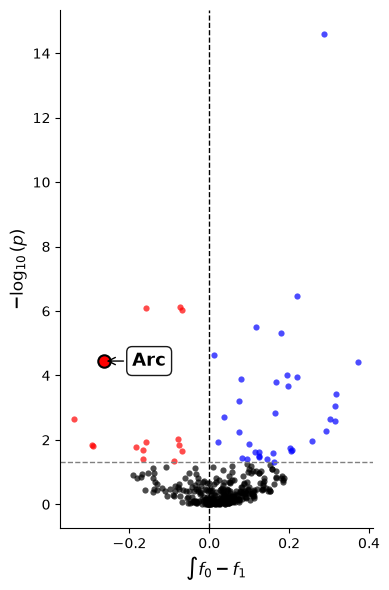

In [12]:
dvg.pl.plot_volcano(adata.varm["dsvg_stats"], n_label=0, highlight_genes="Arc")

<Axes: xlabel='Normalized distance', ylabel='smoothed Arc expression'>

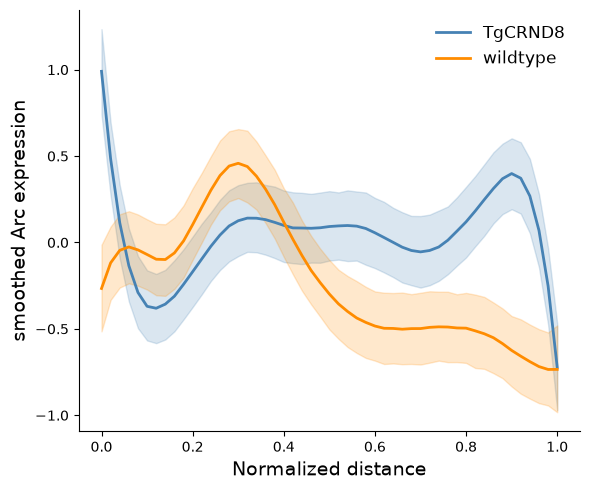

In [9]:
dvg.pl.plot_prediction_curve(adata, gene="Arc")

<Axes: xlabel='gamma_pval', ylabel='count'>

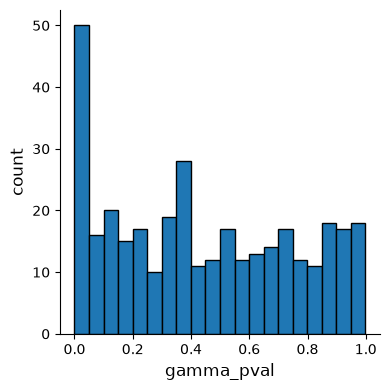

In [14]:
dvg.pl.plot_pvalue_histogram(adata.varm["dsvg_stats"], pvalue="gamma_pval")

In [15]:
adata

AnnData object with n_obs × n_vars = 116982 × 347
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'z_level', 'cell_labels', 'is_noise', 'Dentate_Gyrus', 'condition', 'anchor_bin'
    var: 'mean', 'std'
    uns: 'log1p', 'binned', 'dsvg_curves_condition_categories'
    obsm: 'spatial', 'design_matrix'
    varm: 'dsvg_stats', 'dsvg_preds', 'dsvg_curves_cond0_mean', 'dsvg_curves_cond0_ci_low', 'dsvg_curves_cond0_ci_high', 'dsvg_curves_cond1_mean', 'dsvg_curves_cond1_ci_low', 'dsvg_curves_cond1_ci_high'
    layers: None (.X)